<a href="https://colab.research.google.com/github/ParthHarde/breast-cancer-project/blob/main/breakhis/01_breakhis_download_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = "/content/drive/MyDrive/breast-cancer-project/breakhis"
for sub in ["data/raw", "data/processed", "models", "results"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
print(os.listdir(BASE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['data', 'models', 'results']


In [ ]:
!mkdir -p ~/.kaggle
!cp /content/kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d ambarish/breakhis -p /content/breakhis_zip
!ls -lh /content/breakhis_zip

Dataset URL: https://www.kaggle.com/datasets/ambarish/breakhis
License(s): unknown
100% 3.99G/3.99G [01:05<00:00, 65.7MB/s]

total 4.0G
-rw-r--r-- 1 root root 4.0G Mar 10  2020 breakhis.zip


In [ ]:
!unzip -q /content/breakhis_zip/breakhis.zip -d "{BASE}/data/raw"

In [ ]:
RAW = f"{BASE}/data/raw"
for root, dirs, files in os.walk(RAW):
    depth = root.replace(RAW, "").count(os.sep)
    if depth <= 2:
        print(root.replace(RAW, "") or "/", "| subfolders:", len(dirs), "| files:", len(files))

/ | subfolders: 1 | files: 1
/BreaKHis_v1 | subfolders: 1 | files: 0
/BreaKHis_v1/BreaKHis_v1 | subfolders: 1 | files: 0


In [ ]:
import glob
pngs = glob.glob(f"{RAW}/**/*.png", recursive=True)
print("PNG count:", len(pngs))
print("\n".join(pngs[:5]))

PNG count: 7909
/content/drive/MyDrive/breast-cancer-project/breakhis/data/raw/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/SOB/adenosis/SOB_B_A_14-22549AB/100X/SOB_B_A-14-22549AB-100-001.png
/content/drive/MyDrive/breast-cancer-project/breakhis/data/raw/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/SOB/adenosis/SOB_B_A_14-22549AB/100X/SOB_B_A-14-22549AB-100-002.png
/content/drive/MyDrive/breast-cancer-project/breakhis/data/raw/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/SOB/adenosis/SOB_B_A_14-22549AB/100X/SOB_B_A-14-22549AB-100-003.png
/content/drive/MyDrive/breast-cancer-project/breakhis/data/raw/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/SOB/adenosis/SOB_B_A_14-22549AB/100X/SOB_B_A-14-22549AB-100-004.png
/content/drive/MyDrive/breast-cancer-project/breakhis/data/raw/BreaKHis_v1/BreaKHis_v1/histology_slides/breast/benign/SOB/adenosis/SOB_B_A_14-22549AB/100X/SOB_B_A-14-22549AB-100-005.png


In [ ]:
import pandas as pd
folds = glob.glob(f"{RAW}/**/Folds.csv", recursive=True)
print(folds)
f = pd.read_csv(folds[0])
print(f.shape)
f.head()

['/content/drive/MyDrive/breast-cancer-project/breakhis/data/raw/Folds.csv']
(39545, 4)


,fold,mag,grp,filename
0,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
1,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
2,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
3,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...
4,1,100,train,BreaKHis_v1/histology_slides/breast/benign/SOB...


In [ ]:
import pandas as pd, os

rows = []
for path in pngs:
    name = os.path.basename(path).replace(".png", "")
    parts = name.split("-")                    # ['SOB_B_TA','14','4659','40','001']
    biopsy, cls, subtype = parts[0].split("_")
    rows.append({
        "path": path,
        "class": cls,                          # B or M
        "label": 1 if cls == "M" else 0,       # malignant = 1
        "subtype": subtype,
        "patient_id": f"{parts[1]}-{parts[2]}",
        "magnification": int(parts[3]),
        "img_no": parts[4],
    })

meta = pd.DataFrame(rows)
print(meta.shape)
meta.head()

(7909, 7)


,path,class,label,subtype,patient_id,magnification,img_no
0,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,001
1,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,002
2,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,003
3,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,004
4,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,005


In [ ]:
assert meta["path"].is_unique
assert meta["class"].isin(["B", "M"]).all()
assert meta["magnification"].isin([40, 100, 200, 400]).all()
print("Missing values:\n", meta.isna().sum())

Missing values:
 path             0
class            0
label            0
subtype          0
patient_id       0
magnification    0
img_no           0
dtype: int64


In [ ]:
print("Images per class:\n", meta["class"].value_counts(), "\n")
print("Images per subtype:\n", meta["subtype"].value_counts(), "\n")
print("Images per magnification:\n", meta["magnification"].value_counts().sort_index(), "\n")
print("Patients:", meta["patient_id"].nunique())
print("Patients per class:\n", meta.groupby("class")["patient_id"].nunique(), "\n")
per_pat = meta.groupby("patient_id").size()
print("Images per patient:\n", per_pat.describe())

Images per class:
 class
M    5429
B    2480
Name: count, dtype: int64 

Images per subtype:
 subtype
DC    3451
F     1014
MC     792
LC     626
TA     569
PC     560
PT     453
A      444
Name: count, dtype: int64 

Images per magnification:
 magnification
40     1995
100    2081
200    2013
400    1820
Name: count, dtype: int64 

Patients: 81
Patients per class:
 class
B    24
M    57
Name: patient_id, dtype: int64 

Images per patient:
 count     81.000000
mean      97.641975
std       41.624304
min       38.000000
25%       64.000000
50%       90.000000
75%      125.000000
max      246.000000
dtype: float64


In [ ]:
print((meta.groupby("patient_id")["class"].nunique() > 1).sum())   # should print 0

0


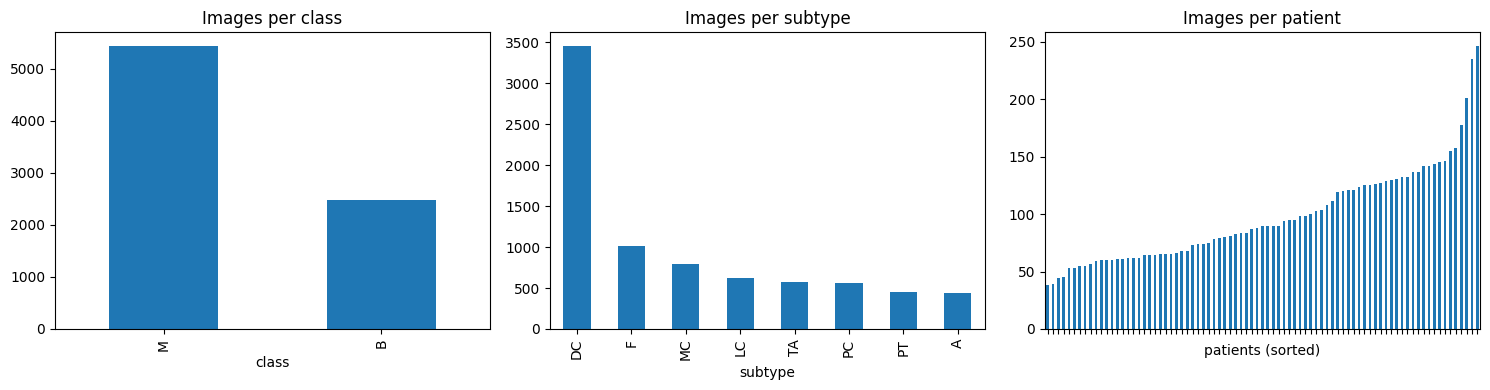

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
meta["class"].value_counts().plot.bar(ax=ax[0], title="Images per class")
meta["subtype"].value_counts().plot.bar(ax=ax[1], title="Images per subtype")

per_pat.sort_values().plot.bar(ax=ax[2], title="Images per patient")
ax[2].set_xticklabels([])          # hide the 82 patient IDs
ax[2].set_xlabel("patients (sorted)")

plt.tight_layout(); plt.show()

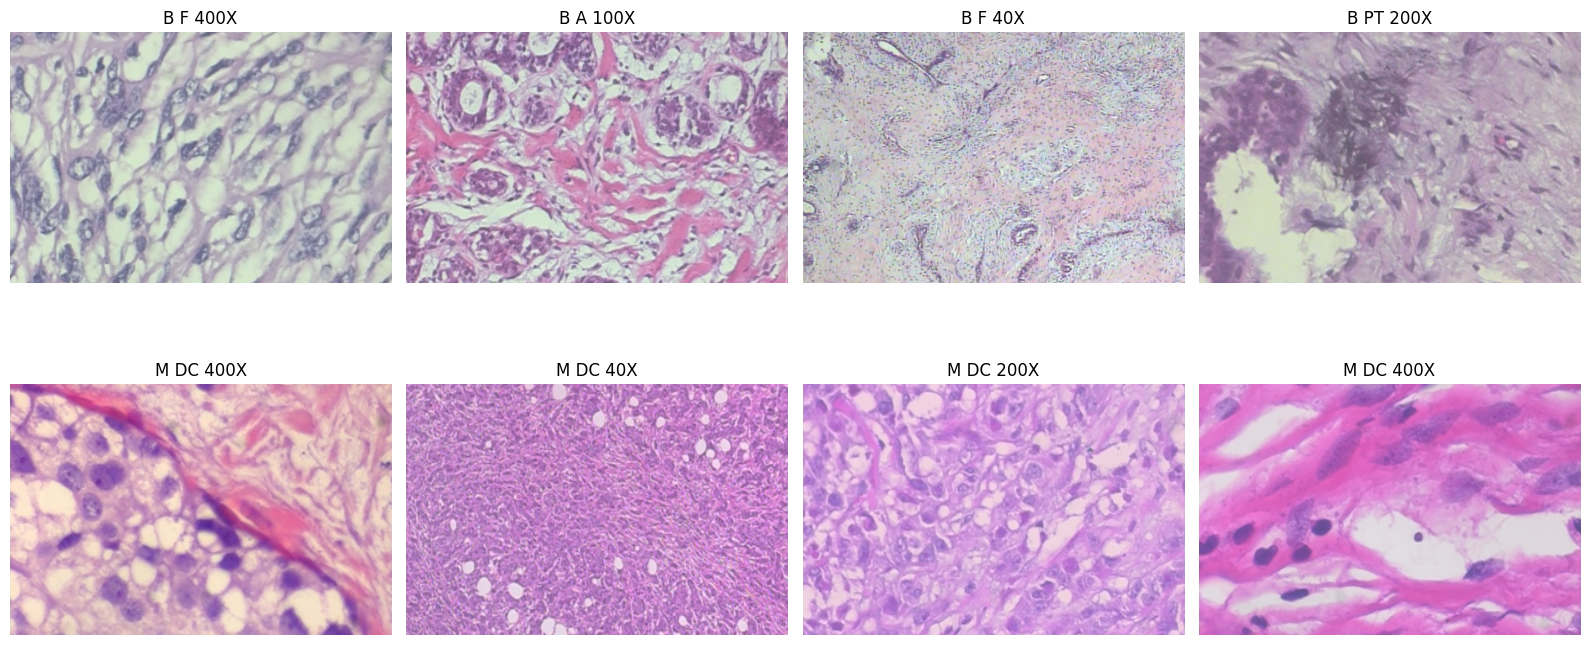

(700, 460)


In [ ]:
from PIL import Image

sample = pd.concat([
    meta[meta["class"] == "B"].sample(4, random_state=42),
    meta[meta["class"] == "M"].sample(4, random_state=42),
])
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r["path"]))
    ax.set_title(f'{r["class"]} {r["subtype"]} {r["magnification"]}X')
    ax.axis("off")
plt.tight_layout(); plt.show()
print(Image.open(sample.iloc[0]["path"]).size)   # image size in pixels

In [ ]:
import pandas as pd, glob, os

pngs = glob.glob(f"{BASE_BH}/**/*.png", recursive=True)
rows = []
for path in pngs:
    name = os.path.basename(path).replace(".png", "")
    parts = name.split("-")                      # ['SOB_B_TA','14','4659','40','001']
    biopsy, cls, subtype = parts[0].split("_")
    rows.append({"path": path, "class": cls, "label": 1 if cls == "M" else 0,
                 "subtype": subtype, "patient_id": f"{parts[1]}-{parts[2]}",
                 "magnification": int(parts[3]), "img_no": parts[4]})
meta = pd.DataFrame(rows)

assert meta["path"].is_unique
assert meta["class"].isin(["B", "M"]).all()
assert meta["magnification"].isin([40, 100, 200, 400]).all()

meta.to_csv(f"{BASE_BH}/data/processed/breakhis_meta.csv", index=False)
print(meta.shape)                                    # expect (7909, 7)
print(meta["class"].value_counts().to_string())      # expect B 2480, M 5429
print("Patients:", meta["patient_id"].nunique())     # expect 82
print("Patients with two classes:", (meta.groupby("patient_id")["class"].nunique() > 1).sum())  # expect 0
meta.head()

(7909, 7)
class
M    5429
B    2480
Patients: 81
Patients with two classes: 0


,path,class,label,subtype,patient_id,magnification,img_no
0,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,001
1,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,002
2,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,003
3,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,004
4,/content/drive/MyDrive/breast-cancer-project/b...,B,0,A,14-22549AB,100,005


In [ ]:
patients = meta.groupby("patient_id").agg(label=("label", "first"), n_images=("path", "size")).reset_index()
print(patients.shape)                  # (82, 3)
print(patients["label"].value_counts())  # 58 malignant, 24 benign

(81, 3)
label
1    57
0    24
Name: count, dtype: int64
